## Project 2

### See Canvas for assignment dates.

****

## Collaboration policy

This is a **group project**. Team assignments are posted on the Canvas assignment page. If you are not assigned to a team, **contact Brent through a private Piazza post by noon on November 4, 2026**.

Be welcoming, considerate, and supportive of your teammates.

**Collaboration is permitted only within your assigned team.** Do not discuss project solutions or share project work with other teams. All submitted work must be your team's own.

If you are unsure whether an activity is allowed, **ask Brent before proceeding**. Violations **will result in a zero for all students involved**.

List each team member's full name in the Markdown cell below.

### Team members

1. Jonathan Chapman
2. Lucas Moore

****
## AI policy

AI may not be used to generate a coding solution. Your team must write and understand all submitted code. If you are unsure whether something is allowed, ask before submitting. Misunderstanding the policy does not excuse a violation.



****
## Honor pledge

Each team member must enter their Onyen and PID below to confirm that they understand and agree to follow the **Collaboration and AI policies**.

1. jmchap   730442025
2. lucasdmo   730670024

****

## Python modules

All Python modules needed to complete this Project are imported below. 

<span style="background-color: #FFFF00">**No other modules are authorized. Points will be deducted if other modules are added.**</span>

Before submitting, make sure your notebook:
- lists all team members,
- acknowledges the honor pledge,
- completes and displays all required calculations and plots,
- uses only the provided imports: NumPy, pandas, Matplotlib, `StandardScalar` from `sklearn.preprocessing`, `math`, and `warnings`, and
- runs from top to bottom without errors.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import math
import warnings
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')

****

### Data Clustering with K-means

The `kdf` dataframe contains 300 unlabeled samples. Each row represents one sample, and the two columns contain its x and y coordinates.

**Helpful resource:** Introduction to unsupervised learning and k-means slides (see Canvas schedule).

****


In [3]:
kdf = pd.read_csv("Kmeans.csv" )
kdf

,x,y
0,1.249031,0.995507
1,4.446048,1.860954
2,2.829059,2.506758
3,2.259368,-1.571176
4,2.050265,2.264782
...,...,...
295,1.287713,0.483150
296,2.476145,2.297358
297,3.569654,2.024624
298,4.068340,2.732174


****

**P1A** (2 Points): Unlabeled Data Visualization.

<img src="p1a.png" width="600" style="float: right"/>

Using the **kdf** dataframe, visualize the unlabeled data in a 2D plot.

To receive full credit, your plotting solution must generate a scatter plot that is identical to the one provided.

**Plot requirements**:
- All the data is used to generate the scatter plot.
- The color used to generate the plot is blue.
- The plot figure size is **9** inches in width and **7** inches in height.
- The default x-axis and y-axis tick values are used.
- The marker shape is `x`.
- The plot grid is enabled.
- Label the axes `x` and `y`, and set the title to `Unlabeled Data`.

Text(0, 0.5, 'y')

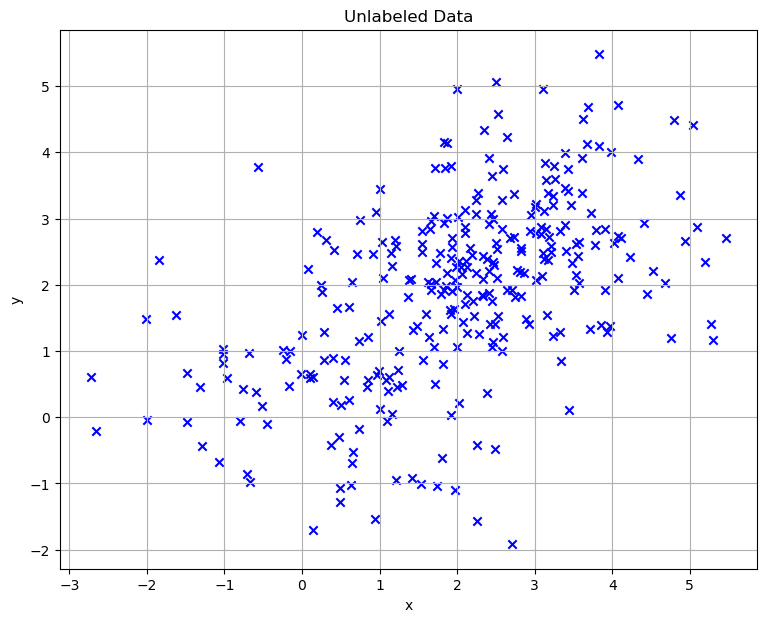

In [4]:
# --------------------------------------
# Add your P1A coding solution below.
# --------------------------------------
fig = plt.figure(figsize = (9, 7))
plt.scatter(
    kdf['x'],
    kdf['y'],
    color = 'blue',
    marker = 'x'
)
plt.title('Unlabeled Data')
plt.grid()
plt.xlabel('x')
plt.ylabel('y')

****

**P1B** (13 Points): Data Clustering and the K-means Algorithm.

<img src="p1b.png" width="600" style="float: right"/>

Using the **kdf** dataframe, run k-means for each number of clusters: $k=1$, $2$, $3$, $4$, $5$, $6$. 

The dashed lines show the path of each cluster's centroid. Specifically, the initial position of the centroid is the ``gray`` diamond, the ``black`` circle indicates the final position, and the dashed line traces the centroid's location at each k-means iteration. 

Inertia is the sum of squared distances from samples to their assigned centroids.

The stopping criteria for your k-means implementation are whichever comes first:
- when the maximum number of iterations ($N$) is reached, or
- when the absolute difference between the inertia at current iteration ($i$) and the previous iteration ($i-1$) is within a defined tolerance ($\epsilon$).

To receive full credit, your solution should produce plots similar to the reference plots. 

**Notes**:
- Initialize centroids randomly within the data bounds (i.e., each coordinate should lie between the minimum and maximum values of that dimension).
- If a cluster has no assigned samples, reinitialize its centroid to a randomly selected data sample.
- <span style="background-color: #FFFF00">Your plots won't be identical because the initial locations of the cluster centroids are randomly generated.</span>.
- The DSML textbook has high-level pseudocode that demonstrates the K-means algorithm (Section 4.6.1). Using the example Python program (Example 4.6) in the DSML textbook is not allowed and will result in an honor code violation. **Do your own work**!
- **If you have questions or are unsure, you and your teammates must ask**.

**Plot Requirements**:
- Arrange the plots in **2 rows and 3 columns**.
- All the data is used to generate the scatter plots.
- The plot figure size is **15** inches in width and **10** inches in height.
- The plot header displays the inertia of the computed clusters.
- The default x-axis and y-axis tick values are used.
- Use marker size **20** for the `x` markers.
- The size of the **diamond** and **circle** marker shapes is $20$.
- The width of the dashed line is $2.5$.
- The colors used to represent cluster one to six (C1-C6) are `'red', 'blue', 'green', 'orange', 'brown', 'purple'`. Use each cluster's color for its samples and dashed centroid path.
- Use opacity **0.4** for the sample markers. Keep centroid markers and dashed paths fully opaque.
- The dashed lines have a `linestyle` of `--`
- The maximum number of iterations (N) is $100$.
- The inertia tolerance ($\epsilon$) is $0.25$. 



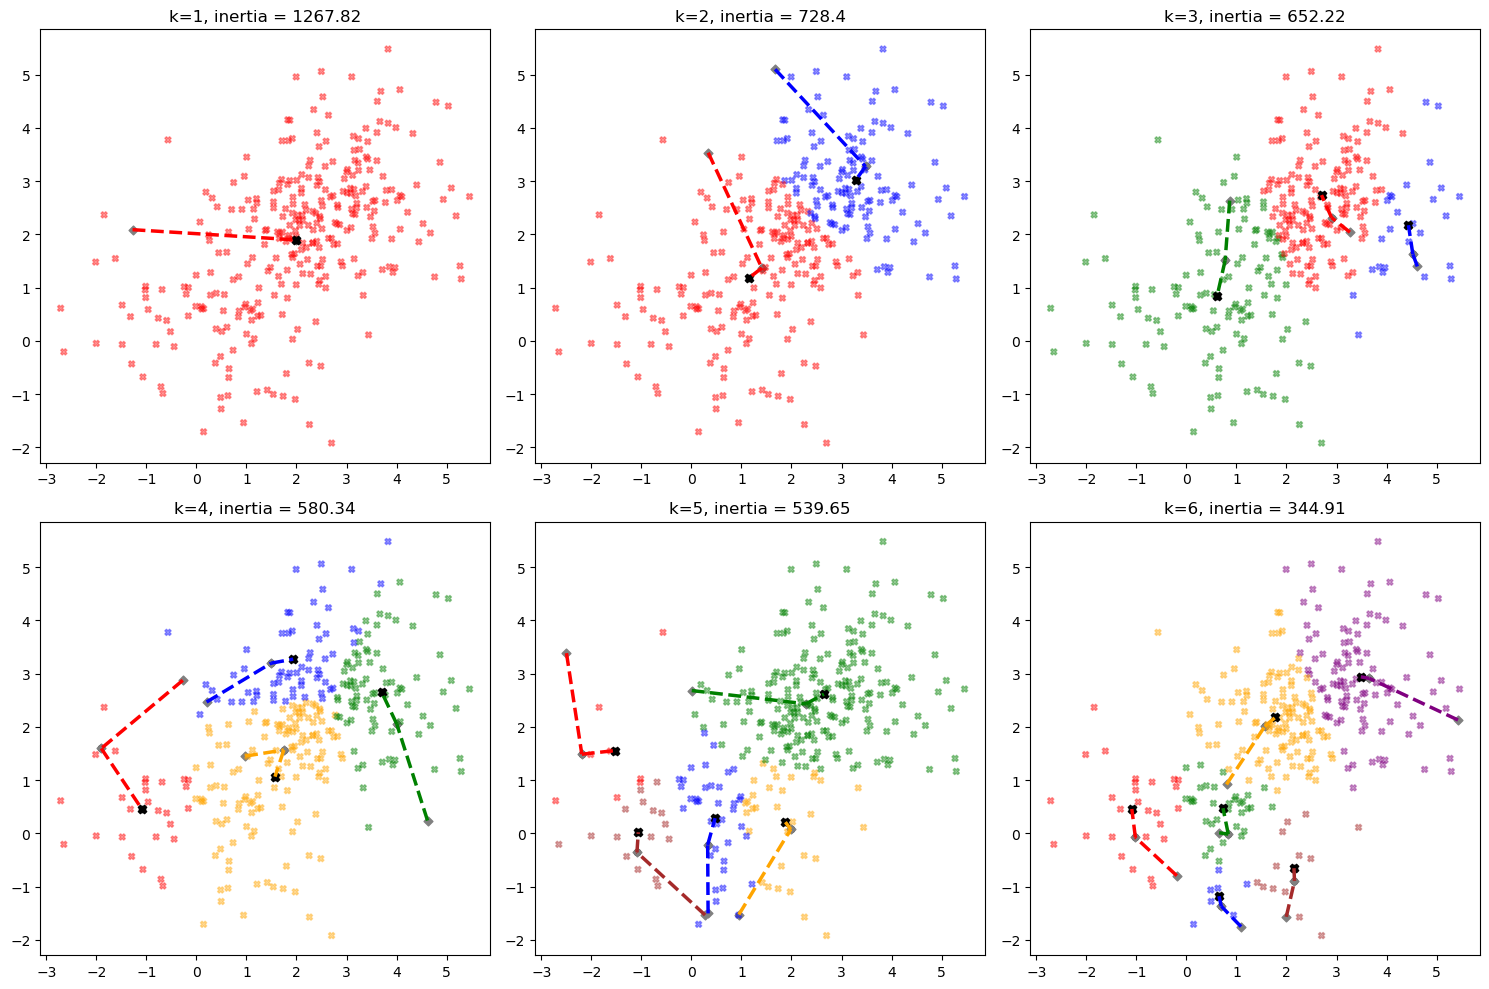

In [5]:
# --------------------------------------
# Add your P1B coding solution below.
# --------------------------------------
def kmeans(
        k:int,
        data: pd.DataFrame = kdf,
        N: int = 100,
        intertia_tol: float = 0.25,
        colors: list = ['red', 'blue', 'green', 'orange', 'brown', 'purple'],
        ax = None
    ):
    centroids = np.array([
        [np.random.uniform(data['x'].min(), data['x'].max()),
        np.random.uniform(data['y'].min(), data['y'].max())]
        for centroid in range(k)
    ])
    data = data.to_numpy()
    inertias = []
    for iter in range(N):
        distances = np.linalg.norm(
            data[:, None] - centroids[None, :], axis = 2
        )
        labels = np.argmin(distances, axis = 1)
        new_centroids = []
        for centroid in range(len(centroids)):
            points = data[labels == centroid]
            if len(points) > 0:
                new_centroids.append(points.mean(axis = 0))
            else:
                new_centroids.append(
                    data[np.random.randint(len(data))]
                )
        new_centroids = np.array(new_centroids)
        inertia = np.sum((data - centroids[labels]) ** 2)
        inertias.append(inertia)
        for index in range(k):
            ax.scatter(
                centroids[index, 0],
                centroids[index, 1],
                marker = 'D',
                c = 'gray',
                s = 20
            )
            ax.scatter(
                new_centroids[index, 0],
                new_centroids[index, 1],
                c = 'black',
                s = 20
            )
            ax.plot(
                [centroids[index, 0], new_centroids[index, 0]],
                [centroids[index, 1], new_centroids[index, 1]],
                linestyle = '--',
                linewidth = 2.5,
                c = colors[index]
            )
        centroids = new_centroids
        try:
            if inertia - inertias[-2] <= intertia_tol:
                break 
        except IndexError:
            continue
    ax.scatter(kdf['x'],
                kdf['y'],
                c = [colors[label] for label in labels],
                alpha = 0.4,
                marker = 'X',
                s = 20)
    ax.scatter(centroids[:, 0], centroids[:, 1], c = 'black', marker = 'X')
    ax.set_title(f'k={k}, inertia = {round(inertia, 2)}')
    return 

fig, axes = plt.subplots(2, 3, figsize = (15, 10))
for k, ax in zip(range(1, 7), axes.flatten()):
    kmeans(k = k, ax = ax)
plt.tight_layout()
plt.show()

****

### Shape Modeling and PCA

The `fdf` dataframe stores one face per column. Each face contains 68 landmarks represented by 136 alternating x and y coordinates:

$$\mathbf{f}_i = (x_0, y_0, x_1, y_1, \ldots, x_{67}, y_{67})^T$$

Thus, the dataframe has dimensions **136 × m**, where m is the number of faces. Each row stores one coordinate value. (<a href="https://ibug.doc.ic.ac.uk/resources/facial-point-annotations/">Dataset reference</a>.)

For visualization, each face vector can be represented as a **68 × 2** matrix, with one landmark $(x_i, y_i)$ per row.

**Helpful resources:**
- Matrix decomposition and PCA slides (see Canvas schedule).
- The <a href="https://d1wqtxts1xzle7.cloudfront.net/32766354/Active_Shape_Models-Their_Training_and_Application_1995CVIU_-libre.pdf?1391178918=&response-content-disposition=inline%3B+filename%3DActive_Shape_Models_Their_Training_and_A.pdf&Expires=1762267168&Signature=FaJwDlw--eTpPE-~yAuvnkbvNy-PA~9oahRHvG88BR882jnAFkfhWRxpwjt7MUeTPG1uAFm7omi-YWjZ5Ykd6X9SM8oWwZubdiwsG-3PGmzbMdAE7CyDO-q5Q9IACzlG7q4LrNpjLRWEV4Y95KhlQ2bxtQBBkjQgemBytXnoSAOEZ-CHsgvguPmItWyX7OAwupd5CNmSy1wc~EdHARKFG7fHTbeaHSDKsfusEIE3YBmkDluKqUzQfPt-uHK8-zrqlk0kAYxpDzqvghvS~k7ZXRrJPoVnuVkZ8aN0-njGiGHTM7j-kOGS8pO4UaTYPV2A7vYBlMJNuaqr58zqf0vCdg__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA">1995 paper</a>, Section 3: Point Distribution Models.

****


In [6]:
fdf = pd.read_csv("./Faces.csv")
fdf_2 = fdf
fdf.shape

(136, 188)

****

**P2A** (3 Points): Mean Face Visualization.

<img src="p2a.png" width="600" style="float: right"/>

Using the **fdf** dataframe, visualize the mean face vector ($\bar{{\bf x}}$) in a 2D scatter plot.

The mean face vector is 

$$\bar{{\bf x}} = (\bar{x}_0,\bar{y}_0,\bar{x}_1,\bar{y}_1, \ldots \bar{x}_{n-1}, \bar{y}_{n-1}),$$

where $\bar{x}_i$ and $\bar{y}_i$ are the mean x and y coordinates of landmark i across all faces.

To receive full credit, your plotting solution must generate a scatter plot that is identical to the one provided.

**Notes**:
- **If you have questions or are unsure, you and your teammates must ask**.

**Plot Requirements**:
- All the data is used to generate the scatter plot.
- The plot figure size is **8** inches in width and **8** inches in height.
- The color used to generate the plot is ``blue``.
- The default x-axis and y-axis tick values are used.
- The marker shape is `o`.
- Label the 68 mean landmarks **1–68**, in their stored order, using font size **10**.
- The plot axis is ``equal``.
- Label the horizontal axis `x` and the vertical axis `y`.
- Set the title to **Mean face vector ($\bar{x}$) landmarks**.

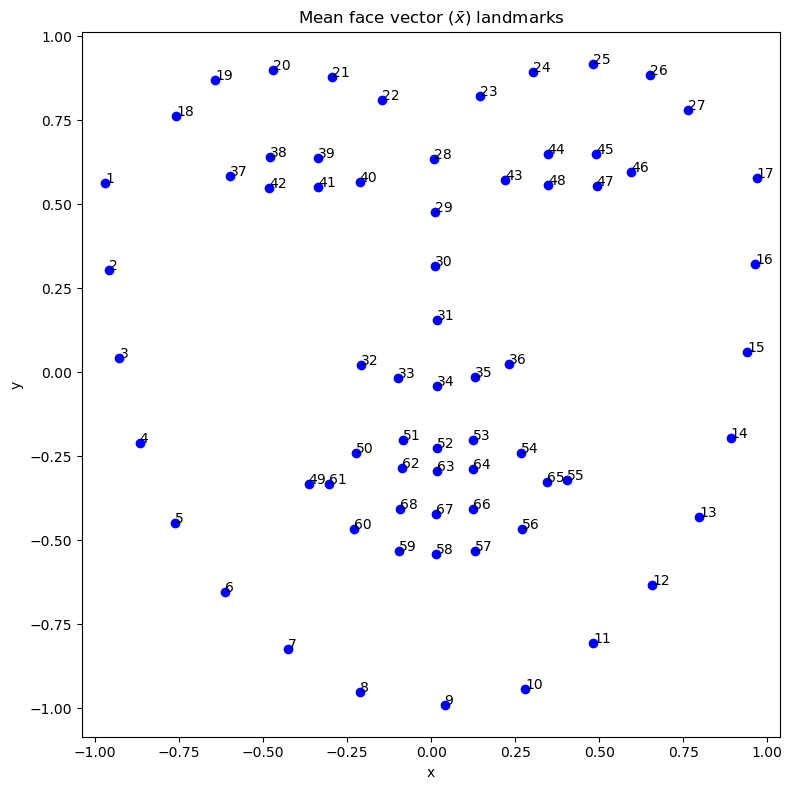

In [14]:
# --------------------------------------
# Add your P2A coding solution below.
# --------------------------------------
plt.figure(figsize=(8, 8))

mean_x = []
mean_y = []
x = True
for i in range(len(fdf)):
    if x:
        mean_x.append(np.mean(fdf.iloc[i]))
    else:
        mean_y.append(np.mean(fdf.iloc[i]))
    x = not x

for i in range(len(mean_x)):
    label = i+1
    plt.annotate(
        label,
        (mean_x[i], mean_y[i]),
        size=10
    )

plt.scatter(mean_x, mean_y, color="blue", marker="o")
plt.title(r"Mean face vector ($\bar{x}$) landmarks")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.tight_layout()
plt.show()








****

**P2B** (12 Points): PCA and Shape Modeling.

<img src="p2b.png" width="600" style="float: right"/>

Using the **fdf** dataframe and the mean shape vector ($\bar{{\bf x}}$), perform principal component analysis (PCA) and visualize the shape space.

Specifically, a new face vector ($\hat{{\bf x}}$) should be generated by

$$\hat{{\bf x}} = \bar{{\bf x}} + \textnormal{V} {\bf b},$$

where $V$ is the eigenvector matrix and ${\bf b}$ is the shape parameters vector. Compute the eigenvector matrix ($V$) and the eigenvalue matrix ($\Lambda$) by performing an eigen decomposition on the covariance matrix ($\Sigma = V \Lambda V^T$). The covariance matrix can be computed using the equation below.

$$\Sigma = \frac{1}{m-1}  \sum_{i=0}^{m-1}({\bf f}_i - \bar{{\bf x}}) ({\bf f}_i - \bar{{\bf x}})^T$$

The shape parameter $b_i$ has standard deviation $\sqrt{\lambda_i}$. Vary it over **$-3\sqrt{\lambda_i}$, $-1.5\sqrt{\lambda_i}$, $0$, $1.5\sqrt{\lambda_i}$, $3\sqrt{\lambda_i}$**, from left to right.

Lastly, as shown in the reference plot, only one shape parameter will be varied at a time. The top, middle, and bottom rows vary **$b_0$, $b_1$, and $b_2$**, respectively, associated with the largest, second-largest, and third-largest eigenvalues. Set all other entries of the **shape parameter vector $\mathbf{b}$** to zero. 

To receive full credit, your solution should produce plots identical to the reference plots. 

**Notes**:
- You **must** use Eigen decomposition (SVD is not allowed, and all points will be forfeited if used).
- **If you have questions or are unsure, you and your teammates must ask**.

**Plot Requirements**:
- The plots must be placed in a $3 \times 5$ grid pattern (see reference plots).
- All the data is used to generate the scatter plots.
- The plot figure size is **9** inches in width and **9** inches in height.
- The color used to generate the plot is ``blue``.
- The default x-axis and y-axis tick values are removed (<a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xticks.html">reference</a>).
- The marker shape is `.` (a dot).
- The default marker size is used.
- Use **equal axis scaling** in every subplot.
- The plot uses a tight layout (<a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.tight_layout.html">reference</a>).


In [7]:
# --------------------------------------
# Add your P2B coding solution below.
# --------------------------------------

















****

### Wine Modeling and PCA

The `wdf` dataframe contains one wine sample per row and 14 columns. The `Class` column identifies the wine class as **1, 2, or 3**. The remaining 13 columns contain numerical measurements describing each sample. (<a href="https://archive.ics.uci.edu/dataset/109/wine">Dataset reference</a>.)

****


In [8]:
wdf = pd.read_csv("./Wine.csv")
wdf

,Class,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


****

**P3** (10 Points): PCA.

<img src="p3.png" width="600" style="float: right"/>

Using the **wdf** dataframe, you are required to perform dimensionality reduction via principal component analysis (PCA) and visualize the resulting space.

Standardize the 13 feature columns using `StandardScaler`. Exclude `Class` from PCA and use it only to color the samples. Use the standardized features for the covariance calculation and projection.
Start by computing the eigenvector matrix ($V$) and the eigenvalue matrix ($\Lambda$) by performing an eigen decomposition on the covariance matrix ($\Sigma = V \Lambda V^T$). The covariance matrix can be computed using the equation below.

$$\Sigma = \frac{1}{m-1}  \sum_{i=0}^{m-1}({\bf f}_i - \bar{{\bf x}}) ({\bf f}_i - \bar{{\bf x}})^T$$

The principal components are found from $V$. The variance along each principal component equals its corresponding eigenvalue.

To visualize the data, project it onto the first two principal components (PC1 and PC2), which capture the greatest variance, and plot the result as a scatter plot, coloring each point with its corresponding class. Arrange two plots side by side: the PC1–PC2 scatter plot on the left and the 13 component variances in descending order on the right. Plot the variances against component numbers 1–13 using a blue line with circle markers.

To receive full credit, your solution should produce plots identical to the reference plots. 

**Notes**:
- You **must** use Eigen decomposition (SVD is not allowed, and all points will be forfeited if used).
- **If you have questions or are unsure, you and your teammates must ask**.

**Plot Requirements**:
- The figure is **10** inches wide and **5** inches tall.
- Class 1 is colored `blue`; Class 2 is colored `orange`; Class 3 is colored `green`. 
- Use opacity **0.5** and marker size **20** for the scatter plot.
- The default marker is used.
- Label the scatter axes **PC1** and **PC2**, and include a legend identifying classes **1, 2, and 3**.


In [9]:
# --------------------------------------
# Add your P3 coding solution below.
# --------------------------------------
















